# README

Companion notebook to reproduce the experiments of Section 1 for the manuscript


> [1] Alexandre d’Aspremont, Frederik Kunstner, Adrien Taylor (2026). "Accelerated gradient methods
in unconstrained convex optimization." To appear in Acta Numerica.

For ease of use, the notebook can be opened in Colab through the following link: 

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AccelerationMethods/Acta-Acceleration/blob/main/Section1_experiments.ipynb)

# Figure 1.2: GD, HBM and NAG on three small problems

Reproduces the three panels of Figure 1.2 (Section 1). Everything is in this notebook: data loading, the three methods, the computation of $f_\star$ and the plot.

| | (i) Least squares | (ii) Logistic regression | (iii) Smoothed $\ell_\infty$ regression |
|---|---|---|---|
| data | diabetes ($n=442$, 10 features) | sonar ($n=208$, 60 features) | diabetes |
| $f(x)$ | $\frac{1}{2n}\|Ax-b\|^2$ | $\frac1n\sum_i \log(1+e^{-y_i\langle a_i,x\rangle}) + \frac\lambda2\|x\|^2$, $\lambda = 1/n$ | $\tau\log\sum_{i=1}^{2n} e^{\ell_i(x)/\tau}$, $\ell = \pm(Ax-b)$, $\tau=0.02$ |
| $L$ | $\lambda_{\max}(A^\top A)/n \approx 4.02$ | $\lambda_{\max}(A^\top A)/(4n)+\lambda \approx 3.06$ | $\max_i\|a_i\|^2/\tau \approx 2489$ |
| $m$ | $\lambda_{\min}(A^\top A)/n \approx 8.6\cdot 10^{-3}$ | $\lambda \approx 4.8\cdot 10^{-3}$ | $0$ |
| iterations | 1000 | 1000 | 3000 |

**Preprocessing.** Features are standardized (mean 0, standard deviation 1) and a column of ones is appended (intercept), so $d = 11$ (diabetes) or $d = 61$ (sonar). The diabetes target $b$ is standardized too. All methods start from $x_0 = 0$.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit, logsumexp, softmax
from sklearn.datasets import load_diabetes

# Sonar data (UCI). Replace by the path of a local copy if you are offline.
SONAR_FILE = "https://archive.ics.uci.edu/ml/machine-learning-databases/undocumented/connectionist-bench/sonar/sonar.all-data"

## The three methods

- GD (1.2): $x_{k+1} = x_k - \alpha\nabla f(x_k)$.
- HBM (1.3): $x_{k+1} = x_k - \alpha\nabla f(x_k) + \beta(x_k - x_{k-1})$, with $x_{-1} = x_0$.
- NAG (1.4): $x_{k+1} = y_k - \alpha\nabla f(y_k)$, $\ y_{k+1} = x_{k+1} + \beta_k(x_{k+1} - x_k)$, with $y_0 = x_0$.

**Parameters choices.**
- GD: $\alpha = 1/L$.
- HBM for the quadratic problem with $m > 0$: Polyak's tuning $\alpha = 4/(\sqrt L+\sqrt m)^2$, $\beta = \big(\tfrac{\sqrt L-\sqrt m}{\sqrt L+\sqrt m}\big)^2$ 
- HBM beyond the quadratic problem: 
    - one of [Ghadimi's tuning](https://arxiv.org/pdf/1412.7457) $\alpha_k=1/2/L\in(0,1/L]$ and $\beta_k=\sqrt{(1-\alpha\mu)(1-\alpha L)}$
    - empirical tuning (done here): $\alpha_k=1/L$, $\beta_k=.9$
- NAG: $\alpha = 1/L$; if $m > 0$, $\beta = \tfrac{\sqrt L-\sqrt m}{\sqrt L+\sqrt m}$; if $m = 0$, $\beta_k = \tfrac{k}{k+3}$.

In [50]:
def gd(f, grad, x0, alpha, n_iter):
    x = x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x = x - alpha * grad(x)
        values.append(f(x))
    return np.array(values)


def hbm(f, grad, x0, alpha, beta, n_iter):
    x, x_prev = x0.copy(), x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x, x_prev = x - alpha * grad(x) + beta * (x - x_prev), x
        values.append(f(x))
    return np.array(values)


def nag(f, grad, x0, alpha, beta, n_iter):
    # beta is either a number or a function k -> beta_k
    x, y = x0.copy(), x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x_next = y - alpha * grad(y)
        beta_k = beta(k) if callable(beta) else beta
        y = x_next + beta_k * (x_next - x)
        x = x_next
        values.append(f(x))
    return np.array(values)


def run_methods(f, grad, x0, L, m, n_iter, quad=False, empirical=True):
    # Parameters of the figure (see the table above).
    rL, rm = np.sqrt(L), np.sqrt(m)
    if quad:
        hbm_alpha, hbm_beta = 4 / (rL + rm) ** 2, ((rL - rm) / (rL + rm)) ** 2
    else:
        if empirical:
            hbm_alpha, hbm_beta = 1 / L, .9
        else:
            hbm_alpha, hbm_beta = 1 / 2 / L, np.sqrt((1 - 1 / 2 / L * m) / 2 )
    if m > 0: 
        nag_beta = (rL - rm) / (rL + rm)
    else:
        nag_beta = lambda k: k / (k + 3)
    return {
        "GD": gd(f, grad, x0, 1 / L, n_iter),
        "HBM": hbm(f, grad, x0, hbm_alpha, hbm_beta, n_iter),
        "NAG": nag(f, grad, x0, 1 / L, nag_beta, n_iter),
    }

## Computing the reference $f_\star$

Closed-form for least squares. For the two other problems $d$ is small and we use a trust-region Newton method.

In [51]:
def solve_with_newton(f, grad, hess, x0):
    res = minimize(f, x0, jac=grad, hess=hess, method="trust-exact", options={"gtol": 1e-13, "maxiter": 1000})
    print(f"  Newton: {res.nit} iterations, |grad f(x*)| = {np.linalg.norm(grad(res.x)):.1e}")
    return res.x

## Data

In [52]:
def standardize(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)


def add_intercept(Z):
    return np.hstack([Z, np.ones((Z.shape[0], 1))])


# Diabetes (Efron, Hastie, Johnstone and Tibshirani 2004): raw data shipped with scikit-learn
diabetes = load_diabetes(scaled=False)
A_diabetes = add_intercept(standardize(diabetes.data))
b_diabetes = standardize(diabetes.target)

# Sonar (Gorman and Sejnowski 1988): 60 features, label "M" (mine) or "R" (rock)
sonar = pd.read_csv(SONAR_FILE, header=None)
A_sonar = add_intercept(standardize(sonar.iloc[:, :60].to_numpy(dtype=float)))
y_sonar = np.where(sonar.iloc[:, 60] == "M", 1.0, -1.0)

print("diabetes:", A_diabetes.shape, "  sonar:", A_sonar.shape)

diabetes: (442, 11)   sonar: (208, 61)


## (i) Least squares on diabetes

$f(x) = \frac{1}{2n}\|Ax-b\|^2$, with $L = \lambda_{\max}(A^\top A)/n$ and $m = \lambda_{\min}(A^\top A)/n$.

In [53]:
def make_least_squares(A, b):
    n = A.shape[0]
    def f(x):
        return np.sum((A @ x - b) ** 2) / (2 * n)
    def grad(x):
        return A.T @ (A @ x - b) / n
    return f, grad


A, b = A_diabetes, b_diabetes
n, d = A.shape
f, grad = make_least_squares(A, b)

eigenvalues = np.linalg.eigvalsh(A.T @ A / n)
L, m = eigenvalues[-1], eigenvalues[0]
f_star = f(np.linalg.lstsq(A, b, rcond=None)[0])
print(f"L = {L:.3g}, m = {m:.3g}, kappa = {L / m:.0f}, f_star = {f_star:.6f}")

values = run_methods(f, grad, np.zeros(d), L, m, n_iter=1000, quad=True)
gaps_ls = {name: v - f_star for name, v in values.items()}

L = 4.02, m = 0.00856, kappa = 470, f_star = 0.241126


## (ii) $\ell_2$-regularized logistic regression on sonar

$f(x) = \frac1n\sum_i \log(1+e^{-y_i\langle a_i,x\rangle}) + \frac\lambda2\|x\|^2$ with $\lambda = 1/n$. Since $\sigma' \leq 1/4$, the Hessian is at most $\frac{1}{4n}A^\top A + \lambda I$, which gives $L = \lambda_{\max}(A^\top A)/(4n) + \lambda$; and $m = \lambda$.

In [54]:
def make_logistic(A, y, lam):
    n, d = A.shape
    def f(x):
        return np.mean(np.logaddexp(0, -y * (A @ x))) + lam / 2 * x @ x
    def grad(x):
        return -A.T @ (y * expit(-y * (A @ x))) / n + lam * x
    def hess(x):
        s = expit(A @ x)
        return A.T @ (A * (s * (1 - s))[:, None]) / n + lam * np.eye(d)
    return f, grad, hess


A, y = A_sonar, y_sonar
n, d = A.shape
lam = 1 / n
f, grad, hess = make_logistic(A, y, lam)

L = np.linalg.eigvalsh(A.T @ A)[-1] / (4 * n) + lam
m = lam
f_star = f(solve_with_newton(f, grad, hess, np.zeros(d)))
print(f"L = {L:.3g}, m = {m:.3g}, kappa = {L / m:.0f}, f_star = {f_star:.6f}")

values = run_methods(f, grad, np.zeros(d), L, m, n_iter=1000)
gaps_logistic = {name: v - f_star for name, v in values.items()}

  Newton: 7 iterations, |grad f(x*)| = 1.4e-11
L = 3.06, m = 0.00481, kappa = 636, f_star = 0.262018


## (iii) Smoothed $\ell_\infty$ regression on diabetes

$\max_i |\langle a_i,x\rangle - b_i|$ is the maximum of the $2n$ affine functions $\ell(x) = \pm(Ax-b)$, smoothed into $f_\tau(x) = \tau\log\sum_{i=1}^{2n} e^{\ell_i(x)/\tau}$ (error at most $\tau\log(2n)$). The Hessian is $\frac1\tau \tilde A^\top(\mathrm{Diag}(p)-pp^\top)\tilde A$ with $p = \mathrm{softmax}(\ell/\tau)$ and $\tilde A = [A; -A]$, so $L = \max_i\|a_i\|^2/\tau$ and $m = 0$.

In [55]:
def make_smoothed_linf(A, b, tau):
    A2, b2 = np.vstack([A, -A]), np.concatenate([b, -b])    # the 2n pieces
    def f(x):
        return tau * logsumexp((A2 @ x - b2) / tau)
    def grad(x):
        return A2.T @ softmax((A2 @ x - b2) / tau)
    def hess(x):
        p = softmax((A2 @ x - b2) / tau)
        Ap = A2.T @ p
        return (A2.T @ (A2 * p[:, None]) - np.outer(Ap, Ap)) / tau
    return f, grad, hess


A, b = A_diabetes, b_diabetes
n, d = A.shape
tau = 0.02
f, grad, hess = make_smoothed_linf(A, b, tau)

L = np.max(np.sum(A ** 2, axis=1)) / tau
m = 0
f_star = f(solve_with_newton(f, grad, hess, np.zeros(d)))
print(f"L = {L:.4g}, m = 0, smoothing error tau log(2n) = {tau * np.log(2 * n):.3f}, f_star = {f_star:.6f}")

values = run_methods(f, grad, np.zeros(d), L, m, n_iter=3000)
gaps_linf = {name: v - f_star for name, v in values.items()}

  Newton: 16 iterations, |grad f(x*)| = 4.5e-11
L = 2489, m = 0, smoothing error tau log(2n) = 0.136, f_star = 1.677366


## Figure

Gaps below $10^{-16}$ (machine precision, possibly negative) are drawn at $10^{-16}$.

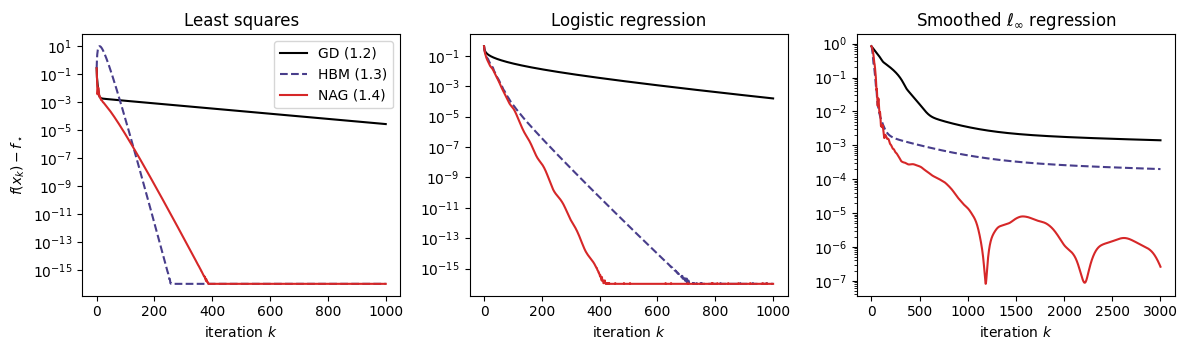

In [56]:
panels = {
    "Least squares": gaps_ls,
    "Logistic regression": gaps_logistic,
    r"Smoothed $\ell_\infty$ regression": gaps_linf,
}
styles = {
    "GD": dict(color="black", label="GD (1.2)"),
    "HBM": dict(color="darkslateblue", linestyle="--", label="HBM (1.3)"),
    "NAG": dict(color="tab:red", label="NAG (1.4)"),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (title, gaps) in zip(axes, panels.items()):
    for name, gap in gaps.items():
        ax.semilogy(np.maximum(gap, 1e-16), **styles[name])
    ax.set_title(title)
    ax.set_xlabel("iteration $k$")
axes[0].set_ylabel(r"$f(x_k) - f_\star$")
axes[0].legend()
fig.tight_layout()
# fig.savefig("fig_intro_experiments.pdf")
plt.show()

## Save into .dat

In [58]:
import os

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

files = {
    "least_squares_diabetes": gaps_ls,
    "logistic_sonar": gaps_logistic,
    "logsumexp_diabetes": gaps_linf,
}
header = "k gd_f hbm_f nag_f"
fmt = ["%d", "%.6e", "%.6e", "%.6e"]

for name, gaps in files.items():
    k = np.arange(len(gaps["GD"]))
    table = np.column_stack([k] + [np.maximum(gaps[method], 1e-16) for method in ("GD", "HBM", "NAG")])
    np.savetxt(f"{DATA_DIR}/{name}.dat", table, header=header, fmt=fmt, comments="")

    # thin copy: every iteration up to k = 50, then about 300 points, and the last one
    step = max(1, len(k) // 300)
    keep = (k <= 50) | (k % step == 0) | (k == k[-1])
    np.savetxt(f"{DATA_DIR}/{name}_thin.dat", table[keep], header=header, fmt=fmt, comments="")
    print(f"{DATA_DIR}/{name}.dat: {len(k)} rows, thin copy: {keep.sum()} rows")

data/least_squares_diabetes.dat: 1001 rows, thin copy: 369 rows
data/logistic_sonar.dat: 1001 rows, thin copy: 369 rows
data/logsumexp_diabetes.dat: 3001 rows, thin copy: 346 rows
